# Prescribed displacements imposed exactly

A prescribed displacement can be imposed exactly as a linear constraint on
the degrees of freedom,
$\boldsymbol{c} = \boldsymbol{Z} \boldsymbol{c}_r + \boldsymbol{c}_{p0} + \lambda \boldsymbol{c}_{p1}$,
where $\boldsymbol{Z}$ is a basis of the null space of the constraints and
$\boldsymbol{c}_{p0}$, $\boldsymbol{c}_{p1}$ are particular solutions for
the constant and the incremented prescribed values, as done by the
null-space method of [panels](https://github.com/saullocastro/panels). The
reduced residual is

$$
\boldsymbol{R}_r(\boldsymbol{c}_r, \lambda) = \boldsymbol{Z}^\top \left(
\boldsymbol{F}_{int}(\boldsymbol{Z} \boldsymbol{c}_r + \boldsymbol{c}_{p0} + \lambda \boldsymbol{c}_{p1}) -
\lambda \boldsymbol{F}_{ext}\right)
$$

and minus its derivative with respect to the load factor,

$$
-\frac{\partial \boldsymbol{R}_r}{\partial \lambda} = \boldsymbol{Z}^\top \left(\boldsymbol{F}_{ext} -
\boldsymbol{K}_T(\boldsymbol{c}) \boldsymbol{c}_{p1}\right)
$$

depends on the configuration and on the load factor. `calc_fext` receives
both when it declares the keyword arguments `c` and `lbd`, see
[callbacks](../callbacks.rst). Under a prescribed displacement alone,
$\boldsymbol{F}_{ext} = \boldsymbol{0}$, the reference vector
`calc_fext(inc=1.)` and the reduced internal force vector both vanish at
equilibrium, and the solvers use $-\partial \boldsymbol{R}/\partial \lambda$
for the displacement scale of the arc-length methods, the predictor of the
first Newton-Raphson increment and the convergence criterion.

In [1]:
%matplotlib inline
import os
import sys

# the helper functions of the tests are imported from the folder tests/
sys.path.insert(0, os.path.join('..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.sparse import csr_matrix

from structsolve import Analysis

def print_table(rows, header=('quantity', 'computed', 'reference', 'rel. diff.')):
    """Rows of (label, computed, reference); the relative difference is
    |computed - reference|/|reference|"""
    w = max(len(header[0]), max(len(r[0]) for r in rows))
    print(f'{header[0]:<{w}}  {header[1]:>16}  {header[2]:>16}  {header[3]:>10}')
    for label, comp, ref in rows:
        rel = abs(comp - ref)/abs(ref)
        print(f'{label:<{w}}  {comp:16.10g}  {ref:16.10g}  {rel:10.2e}')

## The model: three hardening springs in series

Three hardening springs, $f_i(e) = k_i e + a_i e^3$, between a wall and the
nodes 1, 2 and 3, with $k = (100, 150, 200)$ and $a = (20, 40, 60)$, the
displacement of node 3 prescribed, $x_3 = d_0 + \lambda d_1$, and an
optional load $\lambda F$ on node 1, the model of
`tests/test_load_factor_dependent_load.py`. With the null-space method,

$$
\boldsymbol{Z} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \\ 0 & 0 \end{bmatrix}, \qquad
\boldsymbol{c}_{p0} = \{0, 0, d_0\}, \qquad \boldsymbol{c}_{p1} = \{0, 0, d_1\}
$$

and the reduced problem has the two unknowns $\boldsymbol{c}_r = \{x_1, x_2\}$.
`calc_fext(inc, c, lbd)` returns $\lambda (-\partial \boldsymbol{R}_r/\partial \lambda)$
at the configuration and load factor it receives; the reaction of the
support of node 3 is $\boldsymbol{c}_{p1}^\top \boldsymbol{r}/d_1$, with
$\boldsymbol{r} = \boldsymbol{F}_{int}(\boldsymbol{c}) - \lambda \boldsymbol{F}_{ext}$.

Without the load, $F = 0$, the three springs carry the same force $P$, and
the exact solution follows from $\sum_i e_i(P) = x_3$, where $e_i(P)$ is the
real root of $k_i e + a_i e^3 = P$, both solved by `scipy.optimize.brentq`
(method `exact`). With the load, the reference is a dense Newton-Raphson
solution of $\boldsymbol{R}_r = \boldsymbol{0}$ with `numpy.linalg.solve`,
with continuation on the load factor in 20 steps (method
`solve_reference`):

In [2]:
Z = np.array([[1., 0.], [0., 1.], [0., 0.]])


class SpringsProblem(object):
    def __init__(self, k=(100., 150., 200.), a=(20., 40., 60.), d0=0.,
                 d1=1., F=0., with_lbd=True):
        self.k = np.asarray(k)
        self.a = np.asarray(a)
        self.cp0 = np.array([0., 0., d0])
        self.cp1 = np.array([0., 0., d1])
        self.Fext = np.array([F, 0., 0.])
        self.with_lbd = with_lbd
        self.an = None
        # (lbd, c_r) of each call to calc_fext with lbd, and (inc, ||R_r||,
        # number of converged increments) of each call to calc_fint
        self.fext_calls = []
        self.fint_calls = []

    def full(self, c_r, lbd):
        return Z @ c_r + self.cp0 + lbd*self.cp1

    def elongations(self, c):
        return np.array([c[0], c[1] - c[0], c[2] - c[1]])

    def fint_full(self, c):
        k, a = self.k, self.a
        f = k*self.elongations(c) + a*self.elongations(c)**3
        return np.array([f[0] - f[1], f[1] - f[2], f[2]])

    def kT_full(self, c):
        ke = self.k + 3*self.a*self.elongations(c)**2
        return np.array([[ke[0] + ke[1], -ke[1], 0.],
                         [-ke[1], ke[1] + ke[2], -ke[2]],
                         [0., -ke[2], ke[2]]])

    def residual(self, c_r, lbd):
        return Z.T @ (self.fint_full(self.full(c_r, lbd)) - lbd*self.Fext)

    def load_vector(self, c_r, lbd):
        """-dR_r/dlbd"""
        c = self.full(c_r, lbd)
        return Z.T @ (self.Fext - self.kT_full(c) @ self.cp1)

    def reaction(self, c_r, lbd):
        c = self.full(c_r, lbd)
        r = self.fint_full(c) - lbd*self.Fext
        return self.cp1 @ r/self.cp1[2]

    # callables of structsolve.Analysis
    def calc_fext(self, inc=1., silent=True, c=None, lbd=None):
        if c is None:
            return inc*(Z.T @ self.Fext)
        self.fext_calls.append((lbd, c.copy()))
        return inc*self.load_vector(c, lbd)

    def calc_fint(self, c, inc=1., silent=True):
        step = len(self.an.increments) if self.an is not None else 0
        self.fint_calls.append((inc, np.linalg.norm(self.residual(c, inc)),
                                step))
        return Z.T @ self.fint_full(self.full(c, inc))

    def calc_kC(self, c=None, NLgeom=False, inc=1., silent=True):
        if c is None or not NLgeom:
            return csr_matrix(Z.T @ self.kT_full(np.zeros(3)) @ Z)
        return csr_matrix(Z.T @ self.kT_full(self.full(c, inc)) @ Z)

    def calc_kG(self, c=None, NLgeom=False, silent=True):
        return csr_matrix((2, 2))

    def analysis(self, **kwargs):
        if self.with_lbd:
            calc_fext = self.calc_fext
        else:
            calc_fext = lambda inc=1., silent=True: self.calc_fext(inc)
        an = Analysis(calc_fext, self.calc_fint, self.calc_kC, self.calc_kG)
        for key, value in kwargs.items():
            setattr(an, key, value)
        self.an = an
        return an

    def exact(self, lbd):
        """Solution without the load on node 1: the three springs carry the
        same force P, found from sum_i e_i(P) = x_3"""
        x3 = self.cp0[2] + lbd*self.cp1[2]

        def e(P, i):
            return brentq(lambda ei: self.k[i]*ei + self.a[i]*ei**3 - P,
                          -1e4, 1e4, xtol=1e-15, rtol=1e-15)

        def gap(P):
            return sum(e(P, i) for i in range(3)) - x3

        P = 0. if x3 == 0 else brentq(gap, -1e4, 1e4, xtol=1e-14,
                                      rtol=1e-15)
        e1, e2 = e(P, 0), e(P, 1)
        return np.array([e1, e1 + e2]), P

    def solve_reference(self, lbd, tol=1e-14):
        """Dense Newton-Raphson with continuation on the load factor"""
        c_r = np.zeros(2)
        for l in np.linspace(0, lbd, 21)[1:]:
            for _ in range(100):
                R = self.residual(c_r, l)
                if np.linalg.norm(R) <= tol*max(1., np.linalg.norm(
                        self.load_vector(c_r, l))):
                    break
                kT = Z.T @ self.kT_full(self.full(c_r, l)) @ Z
                c_r = c_r + np.linalg.solve(kT, -R)
        return c_r


NL_METHODS = ['NR', 'arc_length_riks', 'arc_length_crisfield']

## The prescribed displacement alone

$x_3 = 0.8 \lambda$, $F = 0$, with the tolerance of the relative force
imbalance only, `relTOL=1e-10`, `absTOL=None`. The force-displacement curve
of the support, $P(x_3)$, against the exact solution, and the number of
evaluations of $-\partial \boldsymbol{R}_r/\partial \lambda$ by `calc_fext`
with `c` and `lbd`: the arc-length solvers evaluate it at the
configurations and load factors of their iterations:

NR                    : 5 increments, 10 calls to calc_fext with c and lbd, at 6 distinct load factors; max |c_r - exact|/max |exact| over the increments 5.7e-11
arc_length_riks       : 4 increments, 13 calls to calc_fext with c and lbd, at 12 distinct load factors; max |c_r - exact|/max |exact| over the increments 3.2e-11
arc_length_crisfield  : 4 increments, 13 calls to calc_fext with c and lbd, at 12 distinct load factors; max |c_r - exact|/max |exact| over the increments 3.2e-11


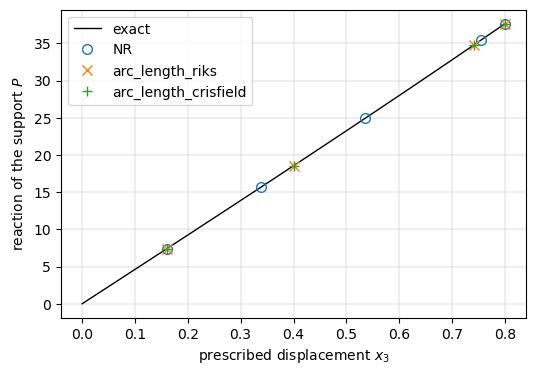

quantity                                                computed         reference  rel. diff.
NR: x_1 at lambda = 1                               0.3666720968      0.3666720968    3.03e-16
NR: x_2 at lambda = 1                                0.613674706       0.613674706    3.62e-16
NR: reaction P at lambda = 1                         37.65317941       37.65317941    3.77e-16
arc_length_riks: x_1 at lambda = 1                  0.3666720968      0.3666720968    4.54e-16
arc_length_riks: x_2 at lambda = 1                   0.613674706       0.613674706    3.62e-16
arc_length_riks: reaction P at lambda = 1            37.65317941       37.65317941    3.77e-16
arc_length_crisfield: x_1 at lambda = 1             0.3666720968      0.3666720968    3.03e-16
arc_length_crisfield: x_2 at lambda = 1              0.613674706       0.613674706    3.62e-16
arc_length_crisfield: reaction P at lambda = 1       37.65317941       37.65317941    3.77e-16


In [3]:
pb_exact = SpringsProblem(d1=0.8)
lbd_curve = np.linspace(0., 1., 101)
P_curve = [pb_exact.exact(l)[1] for l in lbd_curve]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(0.8*lbd_curve, P_curve, 'k-', lw=1, label='exact')
rows = []
for method, mk in zip(NL_METHODS, ['o', 'x', '+']):
    pb = SpringsProblem(d1=0.8)
    an = pb.analysis(NL_method=method, initialInc=0.2, relTOL=1e-10,
                     absTOL=None)
    an.static(NLgeom=True, silent=True)
    lbds = np.asarray(an.increments)
    reactions = [pb.reaction(c_r, l) for l, c_r in zip(an.increments, an.cs)]
    ax.plot(0.8*lbds, reactions, mk, ms=7, mfc='none', label=method)
    err = max(np.abs(c_r - pb.exact(l)[0]).max()/np.abs(pb.exact(l)[0]).max()
              for l, c_r in zip(an.increments, an.cs))
    print(f'{method:22s}: {len(lbds)} increments, {len(pb.fext_calls)} calls '
          f'to calc_fext with c and lbd, at {len(set(l for l, _ in pb.fext_calls))}'
          f' distinct load factors; max |c_r - exact|/max |exact| over the '
          f'increments {err:.1e}')
    ref, P = pb.exact(1.)
    rows += [(f'{method}: x_1 at lambda = 1', an.cs[-1][0], ref[0]),
             (f'{method}: x_2 at lambda = 1', an.cs[-1][1], ref[1]),
             (f'{method}: reaction P at lambda = 1',
              pb.reaction(an.cs[-1], 1.), P)]
ax.set_xlabel('prescribed displacement $x_3$')
ax.set_ylabel('reaction of the support $P$')
ax.grid(True, lw=0.3)
ax.legend()
plt.show()
print_table(rows)

## A constant and an incremented prescribed displacement with a load

A constant prescribed displacement $d_0 = -0.3$, held during the analysis,
with an incremented one, $d_1 = 0.6$, and a load $\lambda F$, $F = 40$, on
node 1: $x_3 = -0.3 + 0.6 \lambda$. At $\lambda = 0$ the constant
displacement alone is not in equilibrium with $\boldsymbol{c}_r = \boldsymbol{0}$:
the first increment starts from a non-null residual. The reference is the
dense Newton-Raphson solution of `solve_reference`:

||R_r(0, 0)|| = 61.62


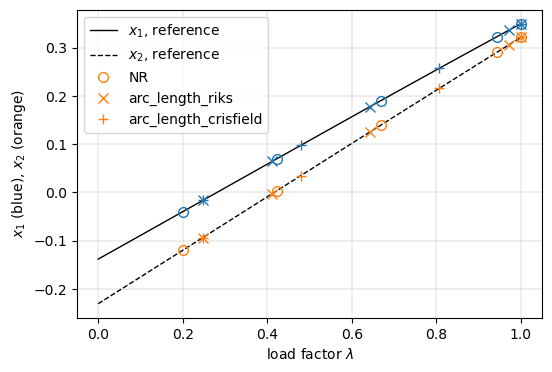

quantity                                         computed         reference  rel. diff.
NR: x_1 at lambda = 1                        0.3492542514      0.3492542514    1.59e-16
NR: x_2 at lambda = 1                           0.3211099         0.3211099    1.73e-16
arc_length_riks: x_1 at lambda = 1           0.3492542514      0.3492542514    0.00e+00
arc_length_riks: x_2 at lambda = 1              0.3211099         0.3211099    0.00e+00
arc_length_crisfield: x_1 at lambda = 1      0.3492542514      0.3492542514    1.30e-14
arc_length_crisfield: x_2 at lambda = 1         0.3211099         0.3211099    5.88e-15


In [4]:
pb_ref = SpringsProblem(d0=-0.3, d1=0.6, F=40.)
print('||R_r(0, 0)|| =', np.linalg.norm(pb_ref.residual(np.zeros(2), 0.)))
lbd_curve = np.linspace(0., 1., 41)
c_curve = np.array([pb_ref.solve_reference(l) for l in lbd_curve])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(lbd_curve, c_curve[:, 0], 'k-', lw=1, label='$x_1$, reference')
ax.plot(lbd_curve, c_curve[:, 1], 'k--', lw=1, label='$x_2$, reference')
rows = []
for method, mk in zip(NL_METHODS, ['o', 'x', '+']):
    pb = SpringsProblem(d0=-0.3, d1=0.6, F=40.)
    an = pb.analysis(NL_method=method, initialInc=0.2, relTOL=1e-11)
    an.static(NLgeom=True, silent=True)
    cs = np.asarray(an.cs)
    ax.plot(an.increments, cs[:, 0], mk, ms=7, mfc='none', color='C0')
    ax.plot(an.increments, cs[:, 1], mk, ms=7, mfc='none', color='C1',
            label=method)
    ref = pb_ref.solve_reference(1.)
    rows += [(f'{method}: x_1 at lambda = 1', cs[-1, 0], ref[0]),
             (f'{method}: x_2 at lambda = 1', cs[-1, 1], ref[1])]
ax.set_xlabel(r'load factor $\lambda$')
ax.set_ylabel('$x_1$ (blue), $x_2$ (orange)')
ax.grid(True, lw=0.3)
ax.legend()
plt.show()
print_table(rows)

## Both together: the null-space method and `constraint_values`

A displacement prescribed by the null-space method, through `calc_fext` with
`c` and `lbd`, combines with the non-homogeneous constraints
$\boldsymbol{C}^\top \boldsymbol{c}_r = \lambda \boldsymbol{d}$ of
`Analysis.constraints` and `Analysis.constraint_values` on the reduced
problem: the solutions of $-\partial \boldsymbol{R}/\partial \lambda$ have
the border $\boldsymbol{d}$, those of the residual a null border. The
springs above, with $x_3 = 1.5 \lambda$, a load $\lambda F$, $F = 80$, on
node 2, and a second prescribed quantity, $e = -0.5$ (the model of
`tests/test_constraint_values_load_factor.py`):

- `'node1'`: $x_1 = \lambda e$, $\boldsymbol{C} = \{1, 0\}$; node 2 is
  then the only free degree of freedom, in equilibrium when
  $f_2(x_2 - x_1) - f_3(x_3 - x_2) = \lambda F$;
- `'relative'`: $x_2 - x_1 = \lambda e$, $\boldsymbol{C} = \{-1, 1\}$;
  $x_1$ is free, in equilibrium when the sum of the forces on the nodes 1
  and 2 balances the load, $f_1(x_1) - f_3(x_3 - x_2) = \lambda F$.

The reference is the same problem with both prescribed quantities
eliminated by hand, its single unknown found by `scipy.optimize.brentq`,
for the five non-linear solvers, the displacement control with the free
degree of freedom as control vector:

node1    NR                               :  8 increments, max |C^T c_r - lambda e| = 2.8e-16
node1    arc_length_riks                  :  5 increments, max |C^T c_r - lambda e| = 1.1e-16
node1    arc_length_crisfield             :  5 increments, max |C^T c_r - lambda e| = 8.3e-17


node1    displacement_control             :  5 increments, max |C^T c_r - lambda e| = 1.1e-16
node1    generalized_displacement_control :  9 increments, max |C^T c_r - lambda e| = 1.1e-16
relative NR                               :  8 increments, max |C^T c_r - lambda e| = 6.7e-16
relative arc_length_riks                  :  5 increments, max |C^T c_r - lambda e| = 2.2e-16
relative arc_length_crisfield             :  5 increments, max |C^T c_r - lambda e| = 2.8e-16


relative displacement_control             :  5 increments, max |C^T c_r - lambda e| = 2.2e-16
relative generalized_displacement_control :  9 increments, max |C^T c_r - lambda e| = 2.2e-16


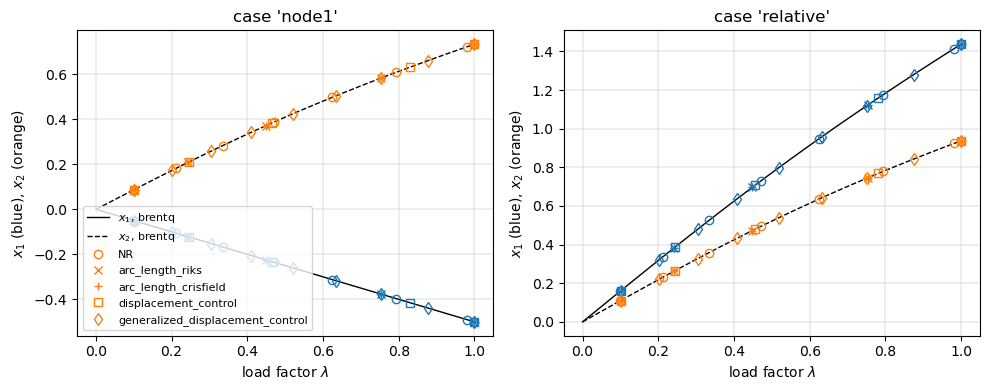


quantity                                                               computed         reference  rel. diff.
node1, NR: x_1 at lambda = 1                                               -0.5              -0.5    5.55e-16
node1, NR: x_2 at lambda = 1                                       0.7338497202      0.7338497202    1.51e-16
node1, arc_length_riks: x_1 at lambda = 1                                  -0.5              -0.5    2.22e-16
node1, arc_length_riks: x_2 at lambda = 1                          0.7338497202      0.7338497202    0.00e+00
node1, arc_length_crisfield: x_1 at lambda = 1                             -0.5              -0.5    0.00e+00
node1, arc_length_crisfield: x_2 at lambda = 1                     0.7338497202      0.7338497202    1.51e-16
node1, displacement_control: x_1 at lambda = 1                             -0.5              -0.5    2.22e-16
node1, displacement_control: x_2 at lambda = 1                     0.7338497202      0.7338497202    1.82e-15
node1, ge

In [5]:
from test_constraint_values_load_factor import (CASES, D1, E, F, METHODS,
                                                make, spring_force)


def reference(p, case, lbd):
    """The configuration of the reduced problem at lbd"""
    x3 = lbd*D1
    if case == 'node1':
        x1 = lbd*E

        def g(x2):
            return (spring_force(p, 1, x2 - x1) - spring_force(p, 2, x3 - x2)
                    - lbd*F)
        x2 = brentq(g, -5., 5., xtol=1e-15, rtol=1e-15)
        return np.array([x1, x2])

    def g(x1):
        x2 = x1 + lbd*E
        return spring_force(p, 0, x1) - spring_force(p, 2, x3 - x2) - lbd*F
    x1 = brentq(g, -5., 5., xtol=1e-15, rtol=1e-15)
    return np.array([x1, x1 + lbd*E])


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
rows = []
for ax, case in zip(axes, CASES):
    p0 = make(case, 'NR')[0]
    lbd_curve = np.linspace(0., 1., 41)
    c_curve = np.array([reference(p0, case, l) for l in lbd_curve])
    ax.plot(lbd_curve, c_curve[:, 0], 'k-', lw=1, label='$x_1$, brentq')
    ax.plot(lbd_curve, c_curve[:, 1], 'k--', lw=1, label='$x_2$, brentq')
    for method, mk in zip(METHODS, ['o', 'x', '+', 's', 'd']):
        p, an = make(case, method)
        an.static(NLgeom=True, silent=True)
        cs = np.asarray(an.cs)
        C = CASES[case]
        viol = max(abs(C @ c - l*E) for l, c in zip(an.increments, an.cs))
        print(f'{case:8s} {method:33s}: {len(cs):2d} increments, '
              f'max |C^T c_r - lambda e| = {viol:.1e}')
        ax.plot(an.increments, cs[:, 0], mk, mfc='none', color='C0')
        ax.plot(an.increments, cs[:, 1], mk, mfc='none', color='C1',
                label=method)
        ref = reference(p, case, 1.)
        rows += [(f'{case}, {method}: x_1 at lambda = 1', cs[-1, 0], ref[0]),
                 (f'{case}, {method}: x_2 at lambda = 1', cs[-1, 1], ref[1])]
    ax.set_title(f"case '{case}'")
    ax.set_xlabel(r'load factor $\lambda$')
    ax.set_ylabel('$x_1$ (blue), $x_2$ (orange)')
    ax.grid(True, lw=0.3)
axes[0].legend(fontsize=8, loc='lower left')
fig.tight_layout()
plt.show()
print()
print_table(rows)